# Lab03 — 01. EDA → Preprocessing → Feature engineering

Một notebook cho toàn bộ luồng chuẩn bị dữ liệu. **MODE="view"** xem artifact đã lưu, không tải dữ liệu/model; đổi **MODE="prepare"** để tạo lại EDA/augmentation trên Kaggle hoặc local. Chuẩn bị dữ liệu không huấn luyện mô hình.

| Phase | Nội dung | Module/file | Artifact trong outputs/ |
|---|---|---|---|
| 1 | Môi trường và data contract | config/frozen_trial.json, src/notebook_runtime.py | environment/config nguồn |
| 2 | Full splits, cân bằng lớp | src/datasets/loader.py | class_distribution.png, data_preview.json |
| 3 | Độ dài và raw examples | scripts/preview_dataset.py | token_length_distribution.png, train_examples.png |
| 4 | Preprocessing/WordPiece | src/models/classifier.py, loader.py | tokenizer_table.png, tokens/IDs/mask |
| 5 | Feature engineering | src/datasets/augmentation.py | augmentation_counts/examples.png, records |
| 6 | Chuyển sang modeling | config/frozen_trial.json | cùng preprocessing/seed, không đổi heldout |

Ảnh hiển thị trực tiếp từ cùng PNG đã lưu. JSON là số liệu kiểm chứng, không thay thế hình. Tập validation của dataset khác với folder validation/ kiểm chứng phần mềm.


## 1. Môi trường và chế độ chạy

Local: cài requirements bằng Python 3.12 rồi dùng kernel đó. Kaggle: bootstrap tạo Python 3.12 riêng; không hạ cấp thư viện kernel. Chỉ thay MODE/DEVICE ở cell đầu.

In [1]:
from pathlib import Path
import subprocess, sys
MODE = "view"  # Notebook 01: view/prepare. Notebook 02: view/train.
DEVICE = "auto"  # auto/cuda/cpu; local CPU được hỗ trợ nhưng chậm.
start = Path.cwd().resolve()
REPO = next((p for p in (start,*start.parents) if (p/"labs/lab03/config/report.json").is_file()), None)
if REPO is None and Path("/kaggle/working").is_dir():
    REPO = Path("/kaggle/working/Lab-DL")
    if not REPO.exists():
        subprocess.run(["git","clone","--branch","lab03","--single-branch","https://github.com/lacthui06/Lab-DL.git",str(REPO)],check=True)
assert REPO is not None, "Mở notebook từ repo đã clone."
sys.path.insert(0,str(REPO))
from labs.lab03.src.notebook_runtime import NotebookSession
session = NotebookSession(REPO, MODE, DEVICE)
session.setup()
from IPython.display import display


Python: 3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
PyTorch: 2.6.0+cpu
CUDA available: False


Mode: view Device request: auto Artifacts: /workspace/Lab-DL-completion/labs/lab03/outputs


## 2. Chuẩn bị dữ liệu hoặc đọc artifact có sẵn

Giữ official train/validation/test 8.530/1.066/1.066. Fit và sinh dữ liệu chỉ từ train. MODE=prepare ghi isolated dataset_preview/augmentation_preview runs mới, không ghi đè run gốc.

In [2]:
session.prepare()
preview = session.read(session.paths["data"]/"data_preview.json")
display(session.table("data", "data_preview.json", "examples"))


,index,text,label
0,4265,"simplistic , silly and tedious .",0
1,4266,"it's so laddish and juvenile , only teenage bo...",0
2,0,the rock is destined to be the 21st century's ...,1
3,1,"the gorgeously elaborate continuation of "" the...",1


## 3. EDA: quy mô và phân bố nhãn

Mỗi split cân bằng hai lớp. Kiểm tra kích thước trước preprocessing để phát hiện subsampling hoặc chia lại không chủ đích.

{'train': 8530, 'validation': 1066, 'test': 1066}

**class_distribution.png**

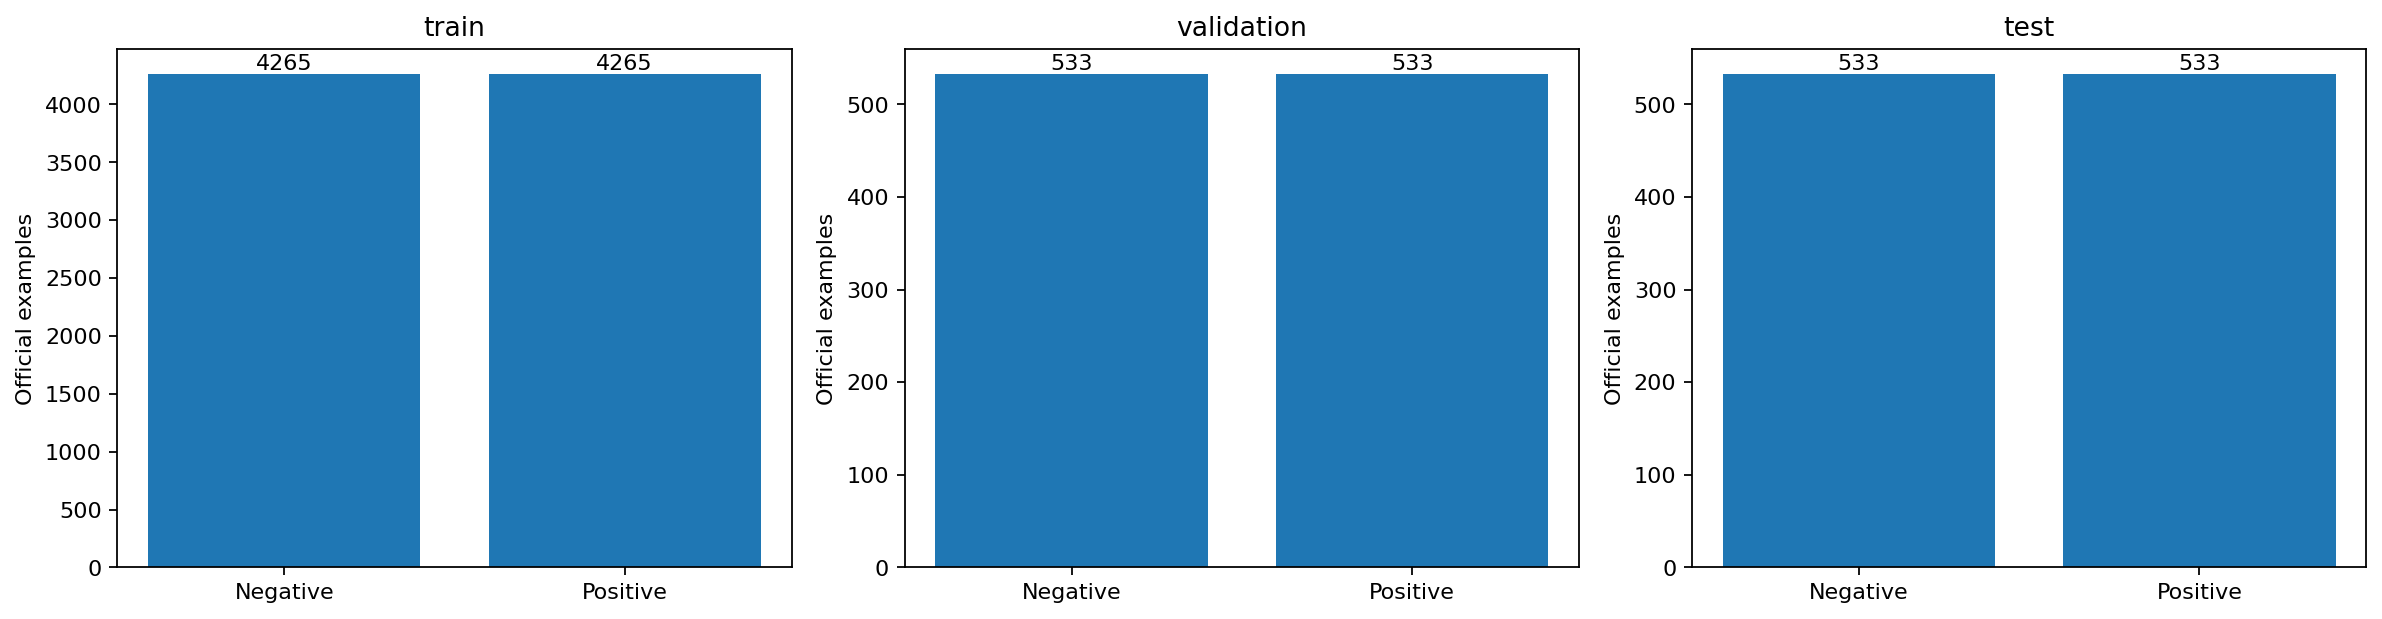

**train_examples.png**

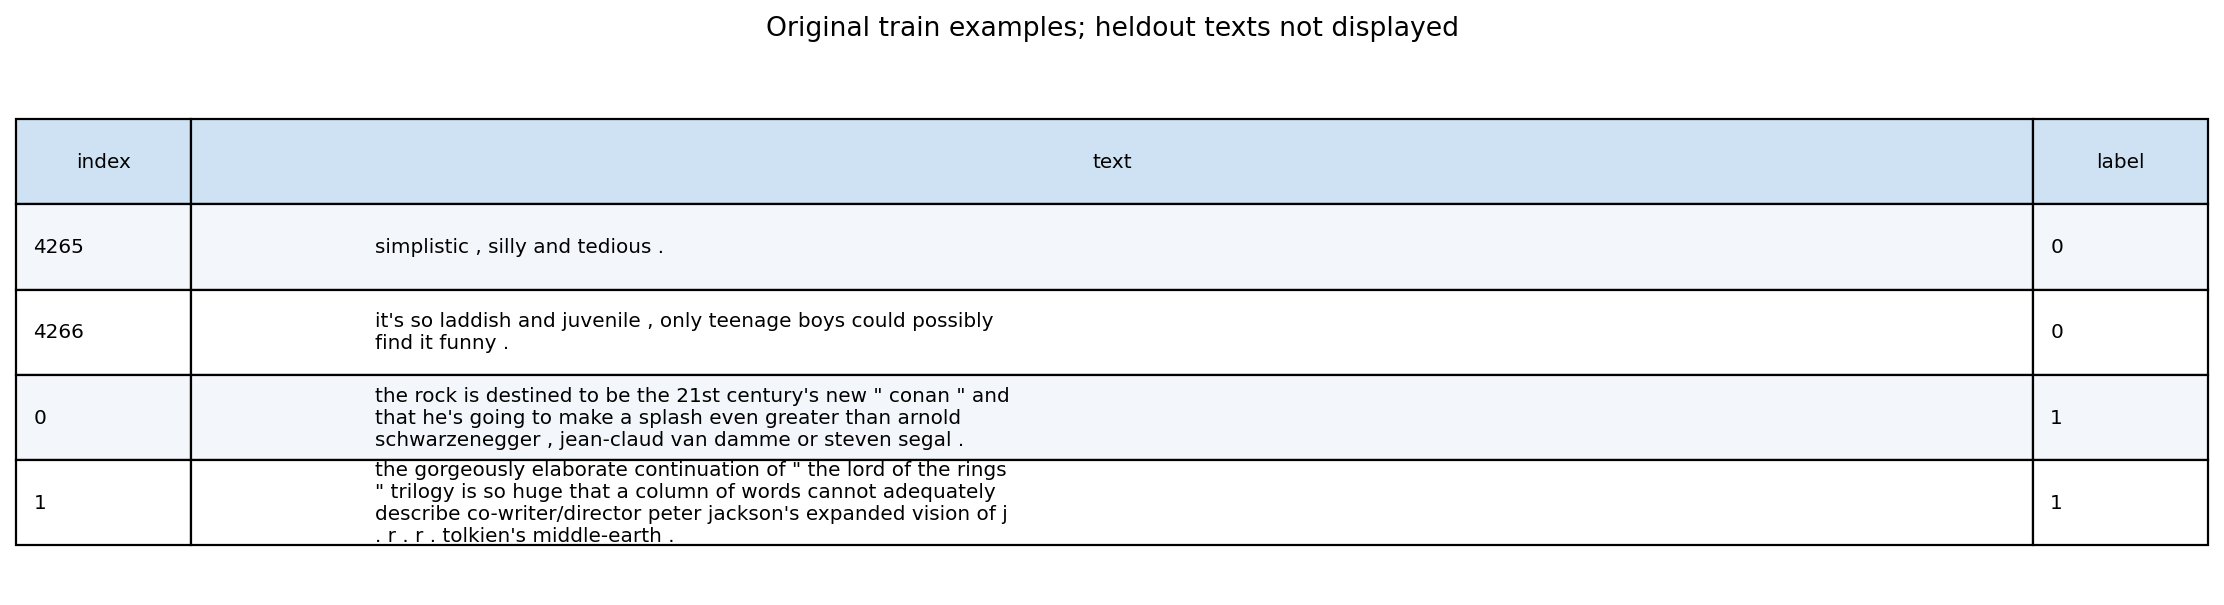

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095637Z_dataset_preview_e2b4d582/class_distribution.png'),
 PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095637Z_dataset_preview_e2b4d582/train_examples.png')]

In [3]:
display(preview["split_sizes"])
session.show("data", ["class_distribution.png", "train_examples.png"])


## 4. Độ dài và preprocessing

Giữ punctuation, phủ định và tương phản; không xóa stopwords theo quy tắc của TF-IDF. WordPiece lowercase theo tokenizer pretrained, max_length=128, dynamic padding ở batch. Train đã đo mean 27.37 tokens, max 78, không có train bị cắt ở 128; không suy rộng sang mọi heldout.

{'mean': 27.368347010550995, 'max': 78, 'truncated_fraction': 0.0}

**token_length_distribution.png**

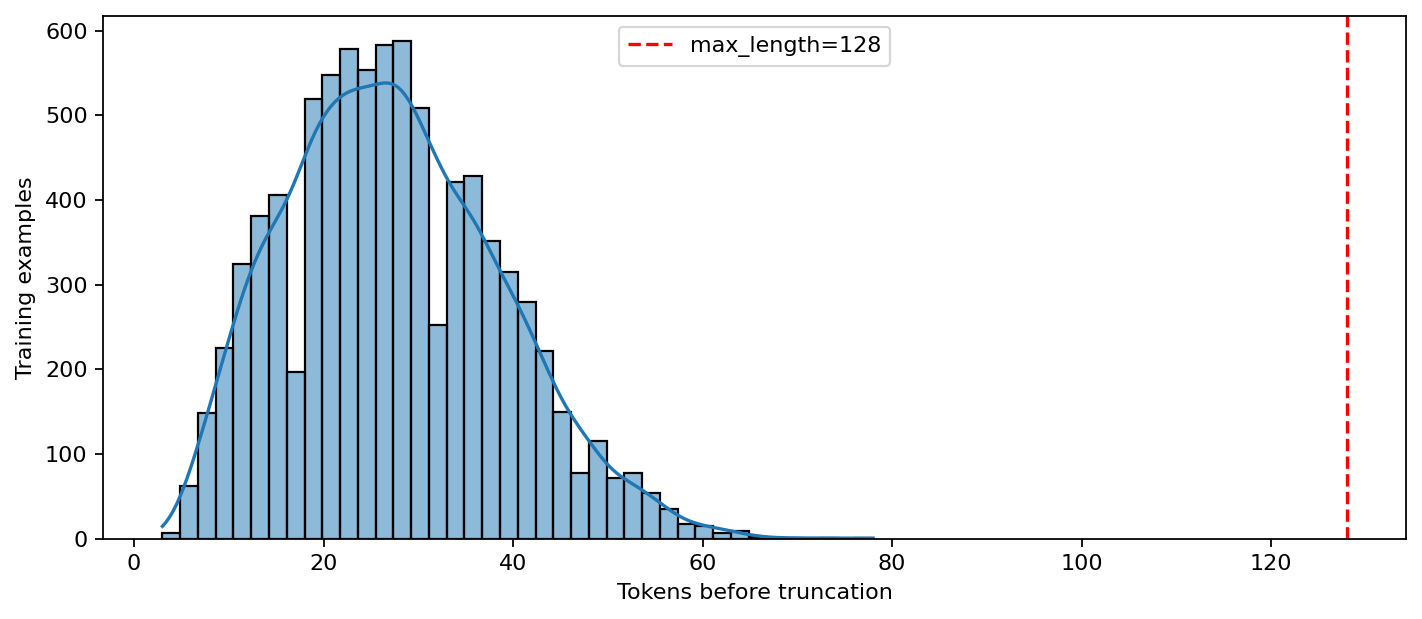

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095637Z_dataset_preview_e2b4d582/token_length_distribution.png')]

In [4]:
display(preview["train_token_lengths"])
session.show("data", ["token_length_distribution.png"])


### Minh họa tokens → IDs → attention mask

Dùng câu minh họa đã lưu của Exercise 1 để thấy WordPiece/IDs/mask. Đây là minh họa tokenizer, không phải thống kê toàn dataset. Attention mask phân biệt padding, không phải attention weights của mô hình.

{'text': 'I love this wonderful movie!',
 'tokens': ['[CLS]', 'i', 'love', 'this', 'wonderful', 'movie', '!', '[SEP]'],
 'input_ids': [101, 1045, 2293, 2023, 6919, 3185, 999, 102],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}

**tokenizer_table.png**

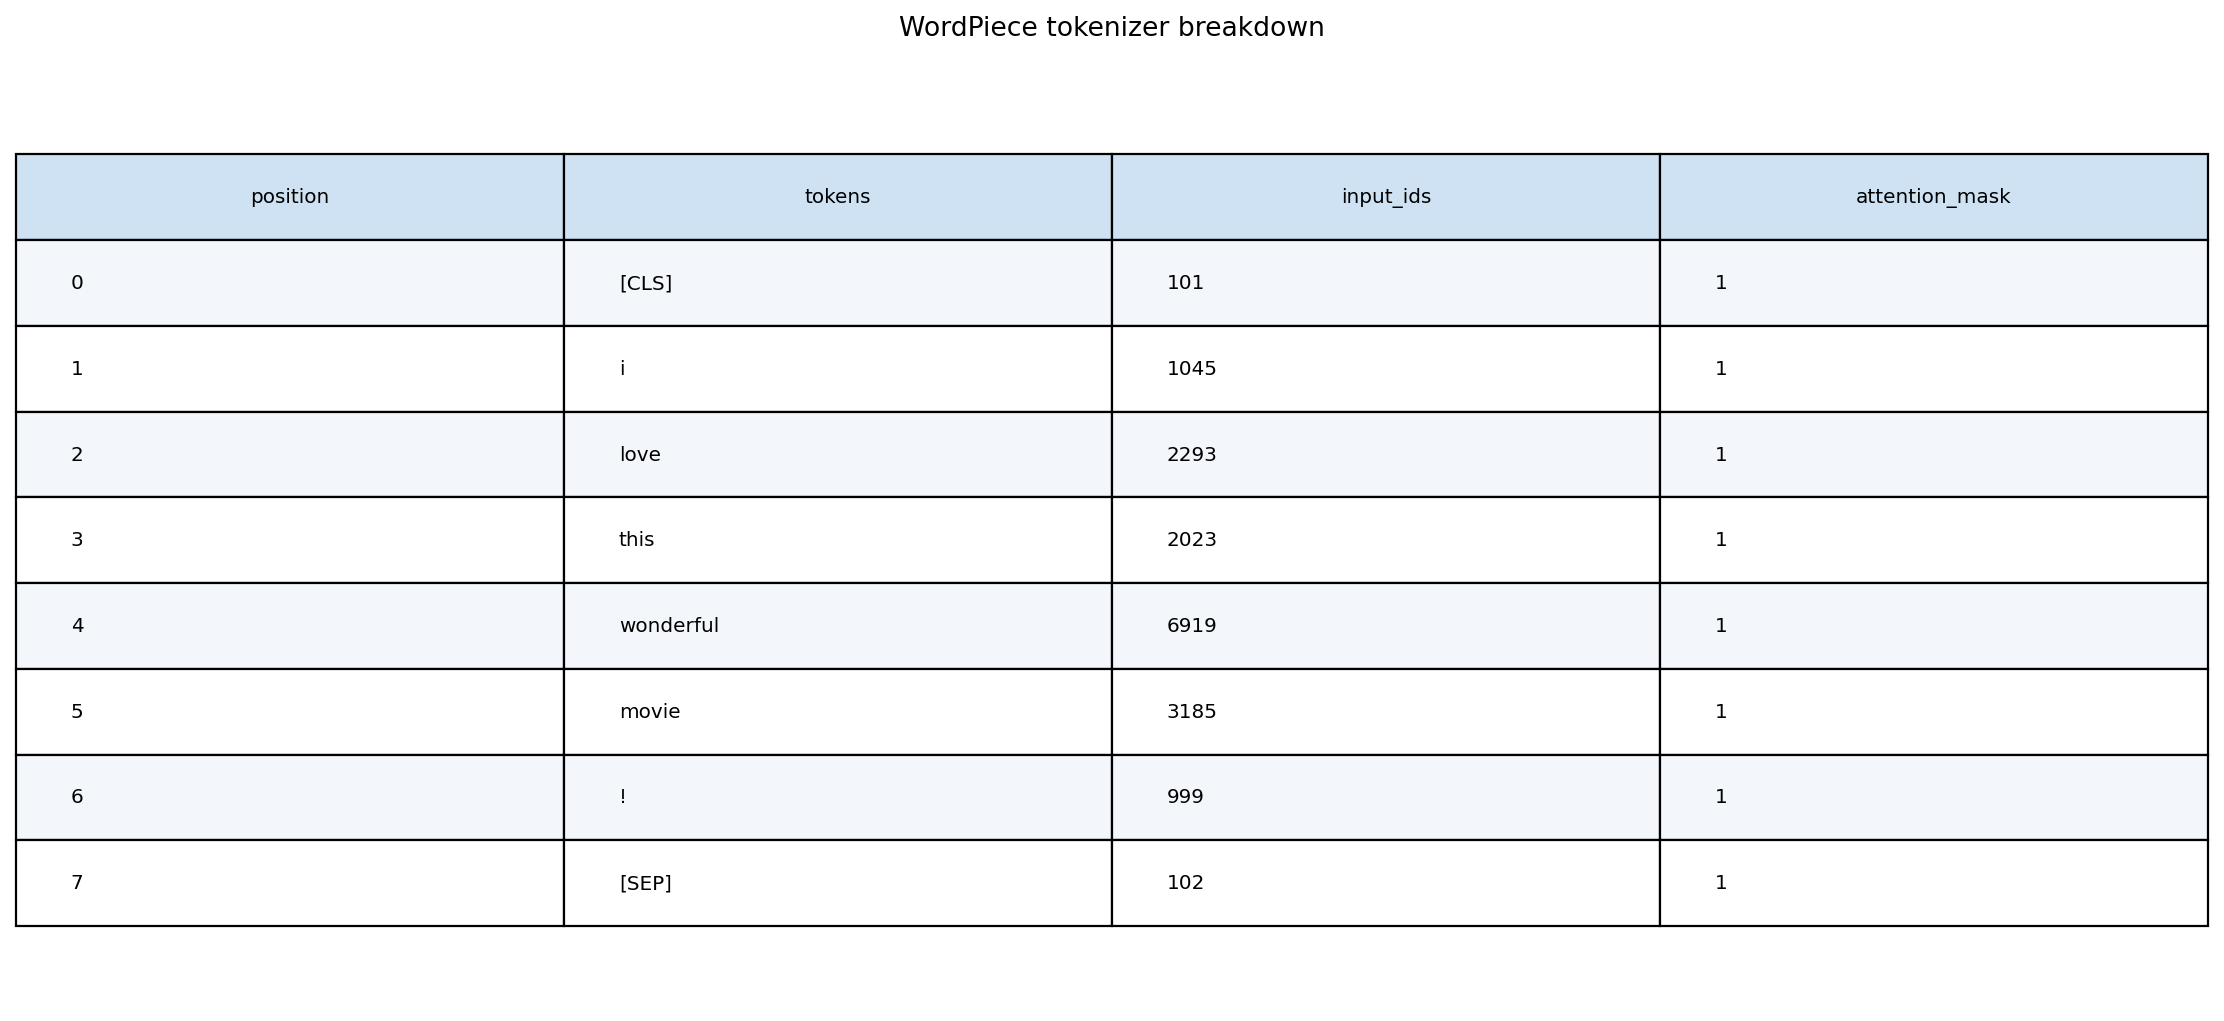

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095630Z_exercise1_analysis_dc3ef4d7/tokenizer_table.png')]

In [5]:
tokenization = session.read(session.paths["exercise1_current"]/"tokenizer_breakdown.json")
display(tokenization)
session.show("exercise1_visuals", ["tokenizer_table.png"])


## 5. Feature engineering và augmentation

DistilBERT nhận token IDs/attention mask; TF-IDF unigram/bigram dành riêng cho baseline modeling. Augmentation thay một từ/cụm cùng cực tính, lọc phủ định/tương phản, chống trùng và cân bằng mẫu thêm. Nhãn kế thừa có thể nhiễu, không phải ground truth mới. Validation/test không tăng mẫu.

{'original_train_size': 8530,
 'added_count': 274,
 'effective_train_size': 8804,
 'added_per_class': {'0': 137, '1': 137}}

**augmentation_counts.png**

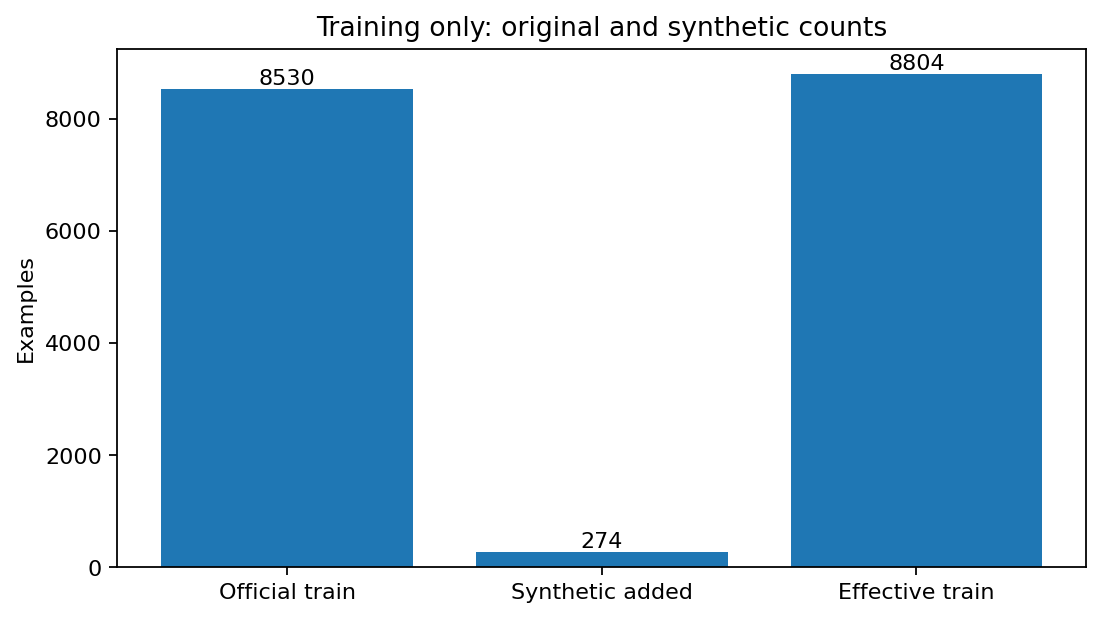

**augmentation_examples.png**

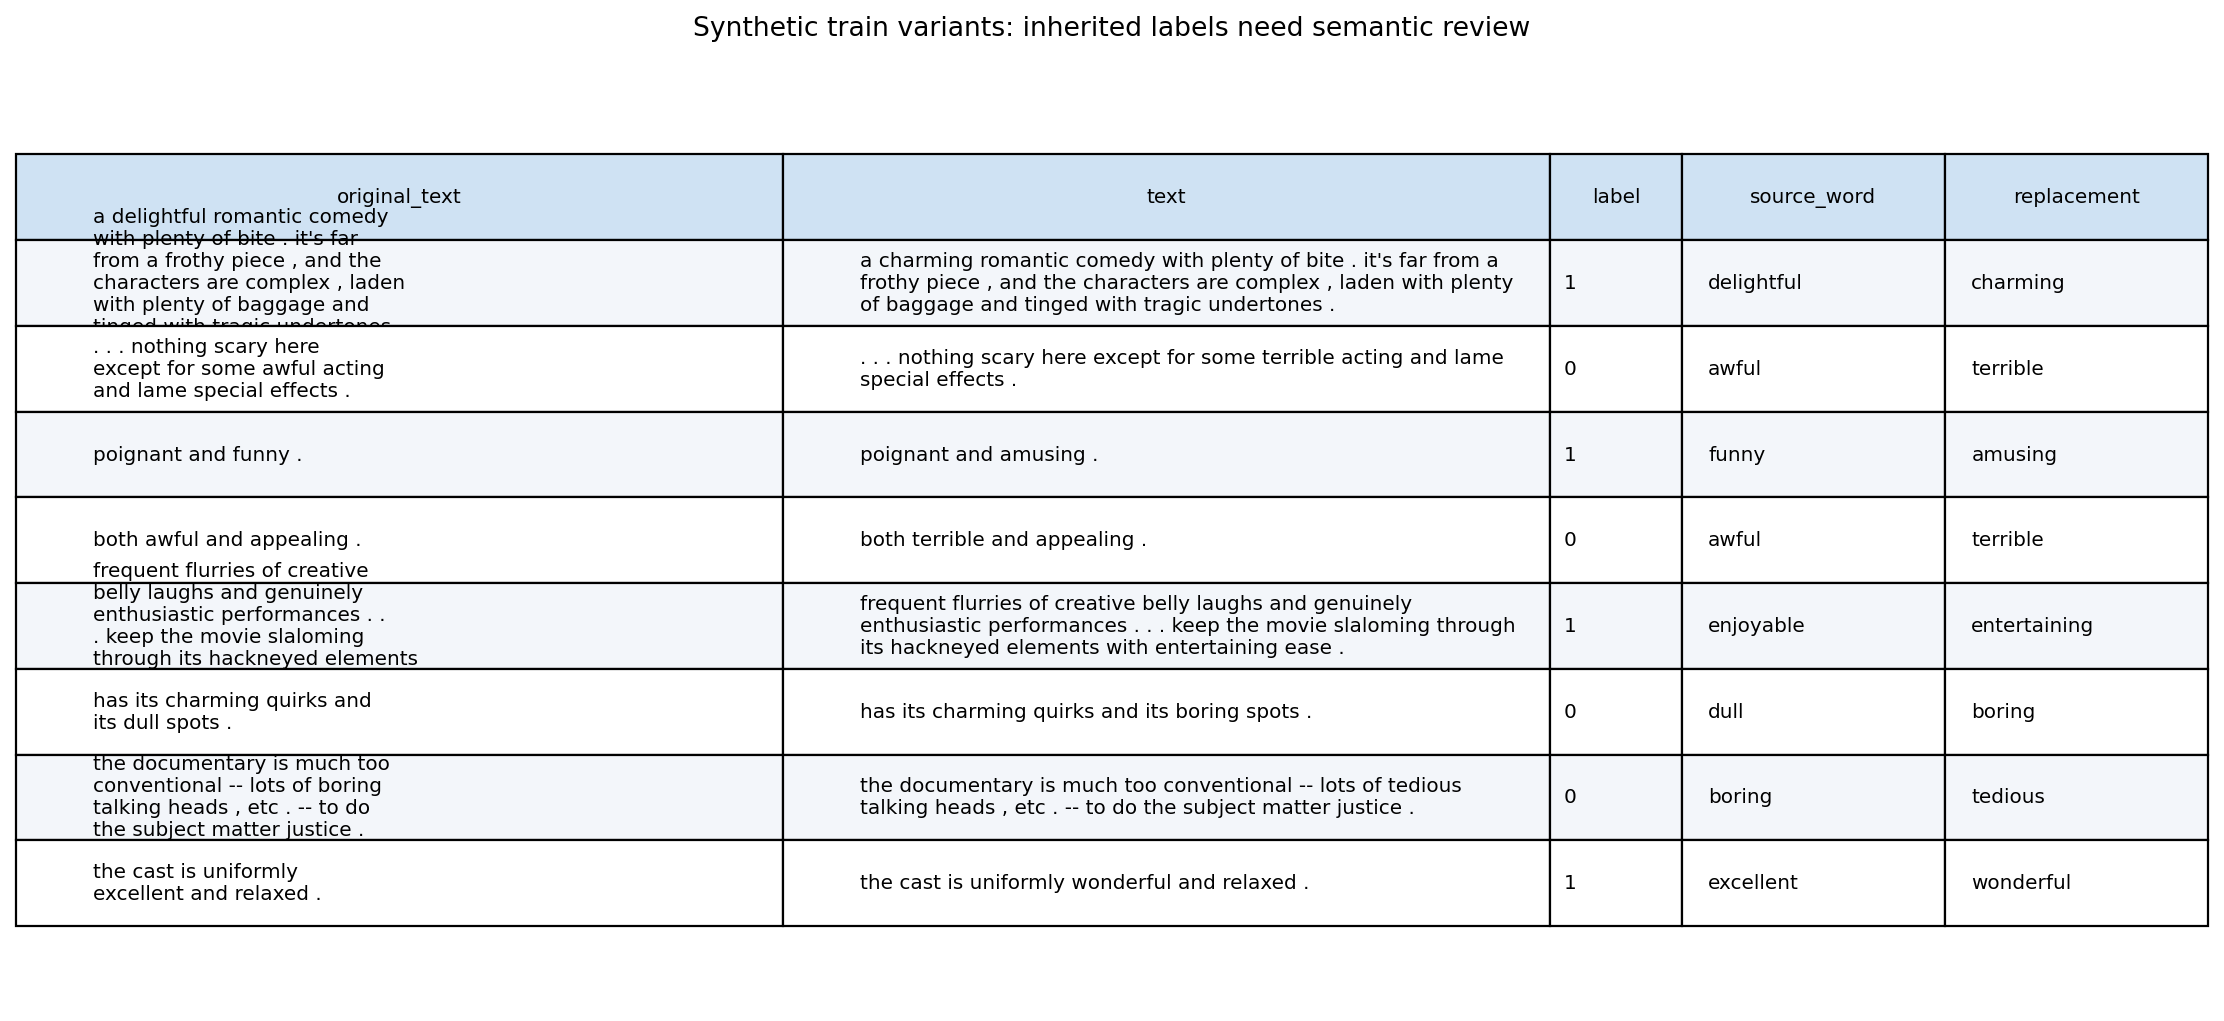

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095647Z_augmentation_preview_acb26523/augmentation_counts.png'),
 PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095647Z_augmentation_preview_acb26523/augmentation_examples.png')]

In [6]:
augmentation = session.read(session.paths["augmentation"]/"augmentation.json")
display({k:augmentation[k] for k in ["original_train_size","added_count","effective_train_size","added_per_class"]})
session.show("augmentation", ["augmentation_counts.png", "augmentation_examples.png"])


### Đọc các biến thể thực tế

Lượt đã đo thêm 274 mẫu, 137 mỗi lớp, effective train 8.804. Số thực tế của lần prepare mới được lấy từ artifact; không ép đủ 25% và không nhân bản y nguyên để đạt quota.

In [7]:
display(session.table("augmentation", "augmentation.json", "records").head(8))
print("Artifacts:", session.paths["data"], session.paths["augmentation"])


,parent_index,original_text,text,label,source_word,replacement,word_start,word_end,method
0,4026,a delightful romantic comedy with plenty of bi...,a charming romantic comedy with plenty of bite...,1,delightful,charming,2,12,single_same_polarity_lexical_substitution_v1
1,5962,. . . nothing scary here except for some awful...,. . . nothing scary here except for some terri...,0,awful,terrible,41,46,single_same_polarity_lexical_substitution_v1
2,2675,poignant and funny .,poignant and amusing .,1,funny,amusing,13,18,single_same_polarity_lexical_substitution_v1
3,6412,both awful and appealing .,both terrible and appealing .,0,awful,terrible,5,10,single_same_polarity_lexical_substitution_v1
4,3126,frequent flurries of creative belly laughs and...,frequent flurries of creative belly laughs and...,1,enjoyable,entertaining,150,159,single_same_polarity_lexical_substitution_v1
5,5243,has its charming quirks and its dull spots .,has its charming quirks and its boring spots .,0,dull,boring,32,36,single_same_polarity_lexical_substitution_v1
6,7647,the documentary is much too conventional -- lo...,the documentary is much too conventional -- lo...,0,boring,tedious,52,58,single_same_polarity_lexical_substitution_v1
7,976,the cast is uniformly excellent and relaxed .,the cast is uniformly wonderful and relaxed .,1,excellent,wonderful,22,31,single_same_polarity_lexical_substitution_v1


Artifacts: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095637Z_dataset_preview_e2b4d582 /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095647Z_augmentation_preview_acb26523


## 6. Chuyển sang modeling

Mở [02_modeling.ipynb](02_modeling.ipynb). Modeling gọi lại cùng loader/tokenizer/augmentation, seed và config; không chép logic từ notebook này. Không cần chạy prepare lại chỉ để xem report. Dữ liệu gốc không commit vào Git; artifacts nhẹ được lưu outputs/ để tái dùng khi viết báo cáo.

Quyết định và phân tích chi tiết: [description](../description_lab_03.md), [walkthrough](../walkthrough_lab_03.md).